<a href="https://colab.research.google.com/github/DevNova11/EDA2026/blob/main/EXP7_25.08.2026/IrisDataAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

iris_df = pd.read_csv('/content/Iris.csv')

display(iris_df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [11]:
print('DataFrame Info:')
print(iris_df.info())

print('\nDataFrame Description:')
display(iris_df.describe())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

DataFrame Description:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


### Exploratory Data Analysis with Visualizations

Now that we have loaded and inspected the basic information of the dataset, let's perform some exploratory data analysis using visualizations to understand the distributions of features and relationships between them.

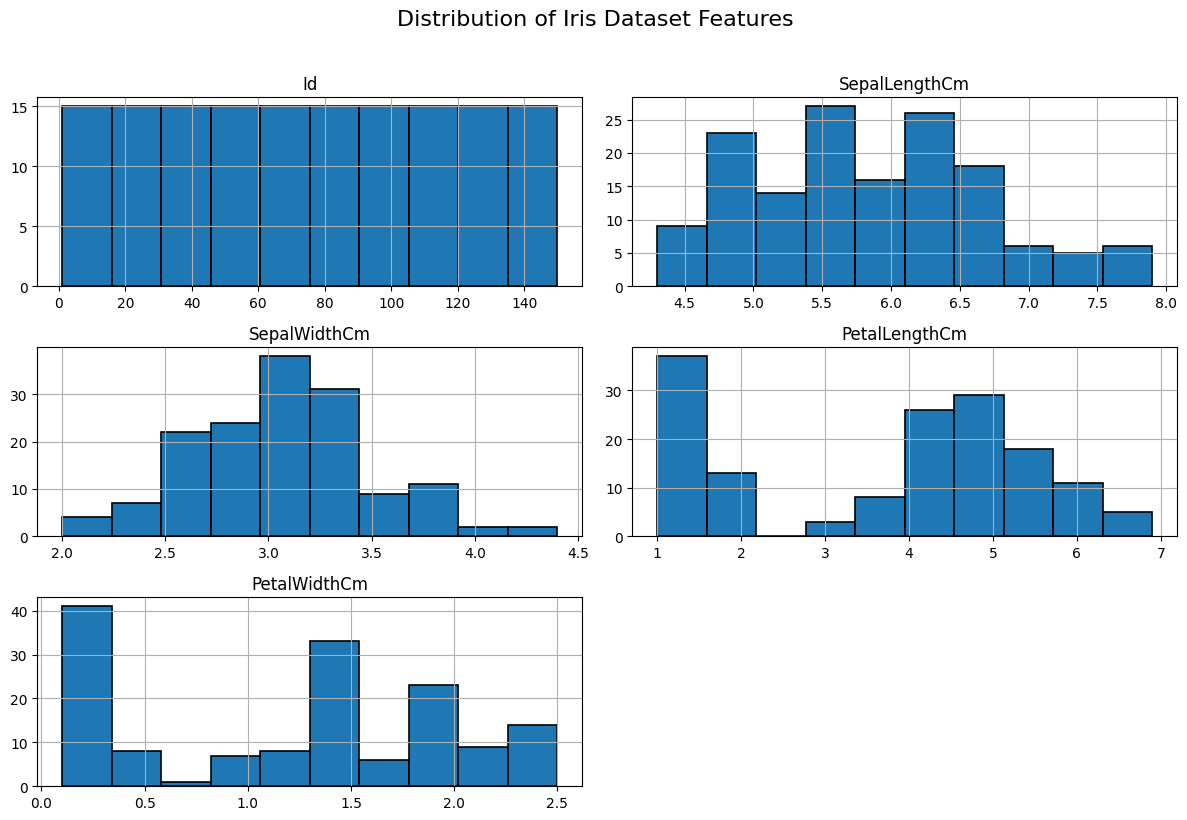

In [12]:
iris_df.hist(edgecolor='black', linewidth=1.2, figsize=(12, 8))
plt.suptitle('Distribution of Iris Dataset Features', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

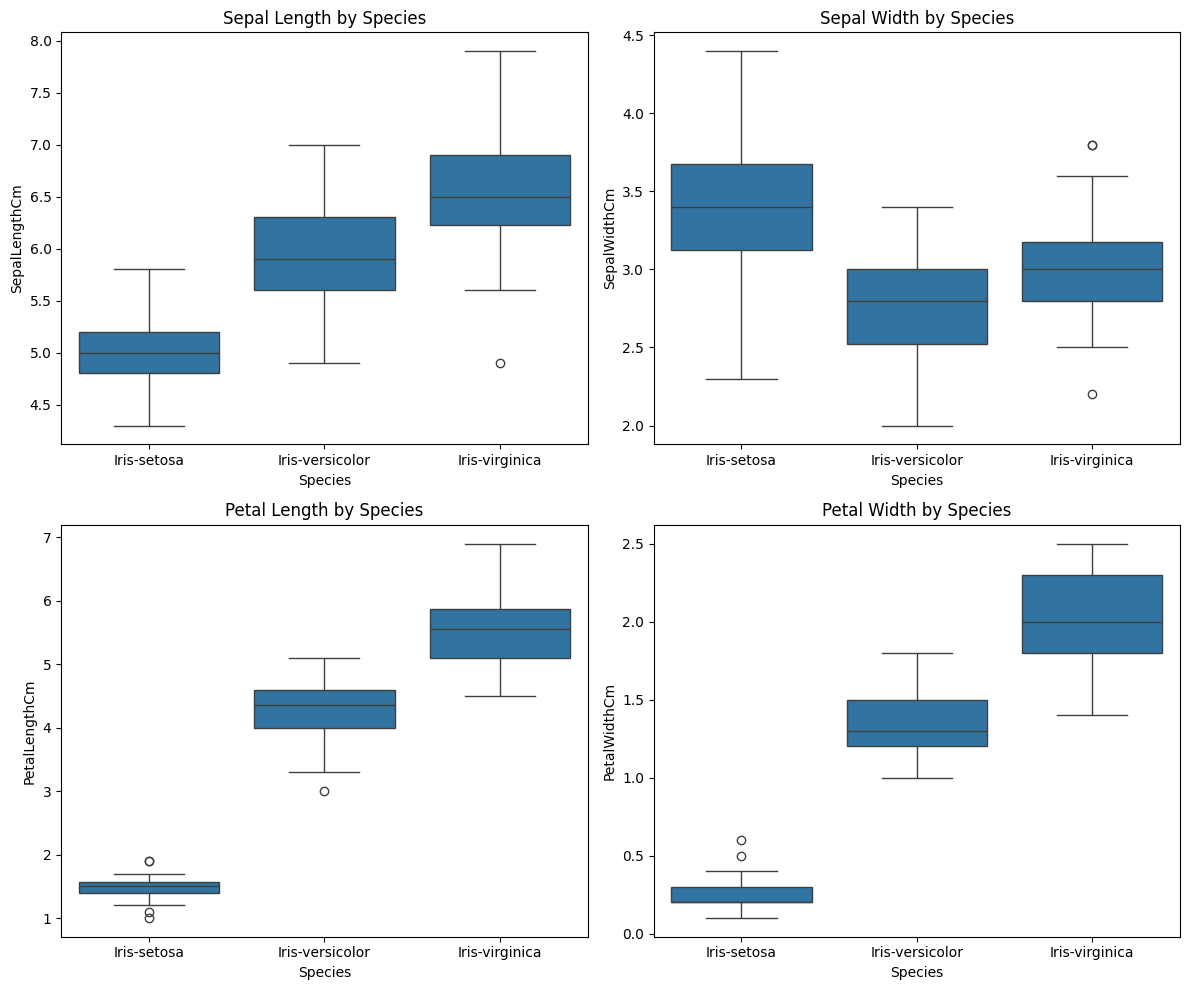

In [13]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
sns.boxplot(x='Species', y='SepalLengthCm', data=iris_df)
plt.title('Sepal Length by Species')

plt.subplot(2, 2, 2)
sns.boxplot(x='Species', y='SepalWidthCm', data=iris_df)
plt.title('Sepal Width by Species')

plt.subplot(2, 2, 3)
sns.boxplot(x='Species', y='PetalLengthCm', data=iris_df)
plt.title('Petal Length by Species')

plt.subplot(2, 2, 4)
sns.boxplot(x='Species', y='PetalWidthCm', data=iris_df)
plt.title('Petal Width by Species')

plt.tight_layout()
plt.show()

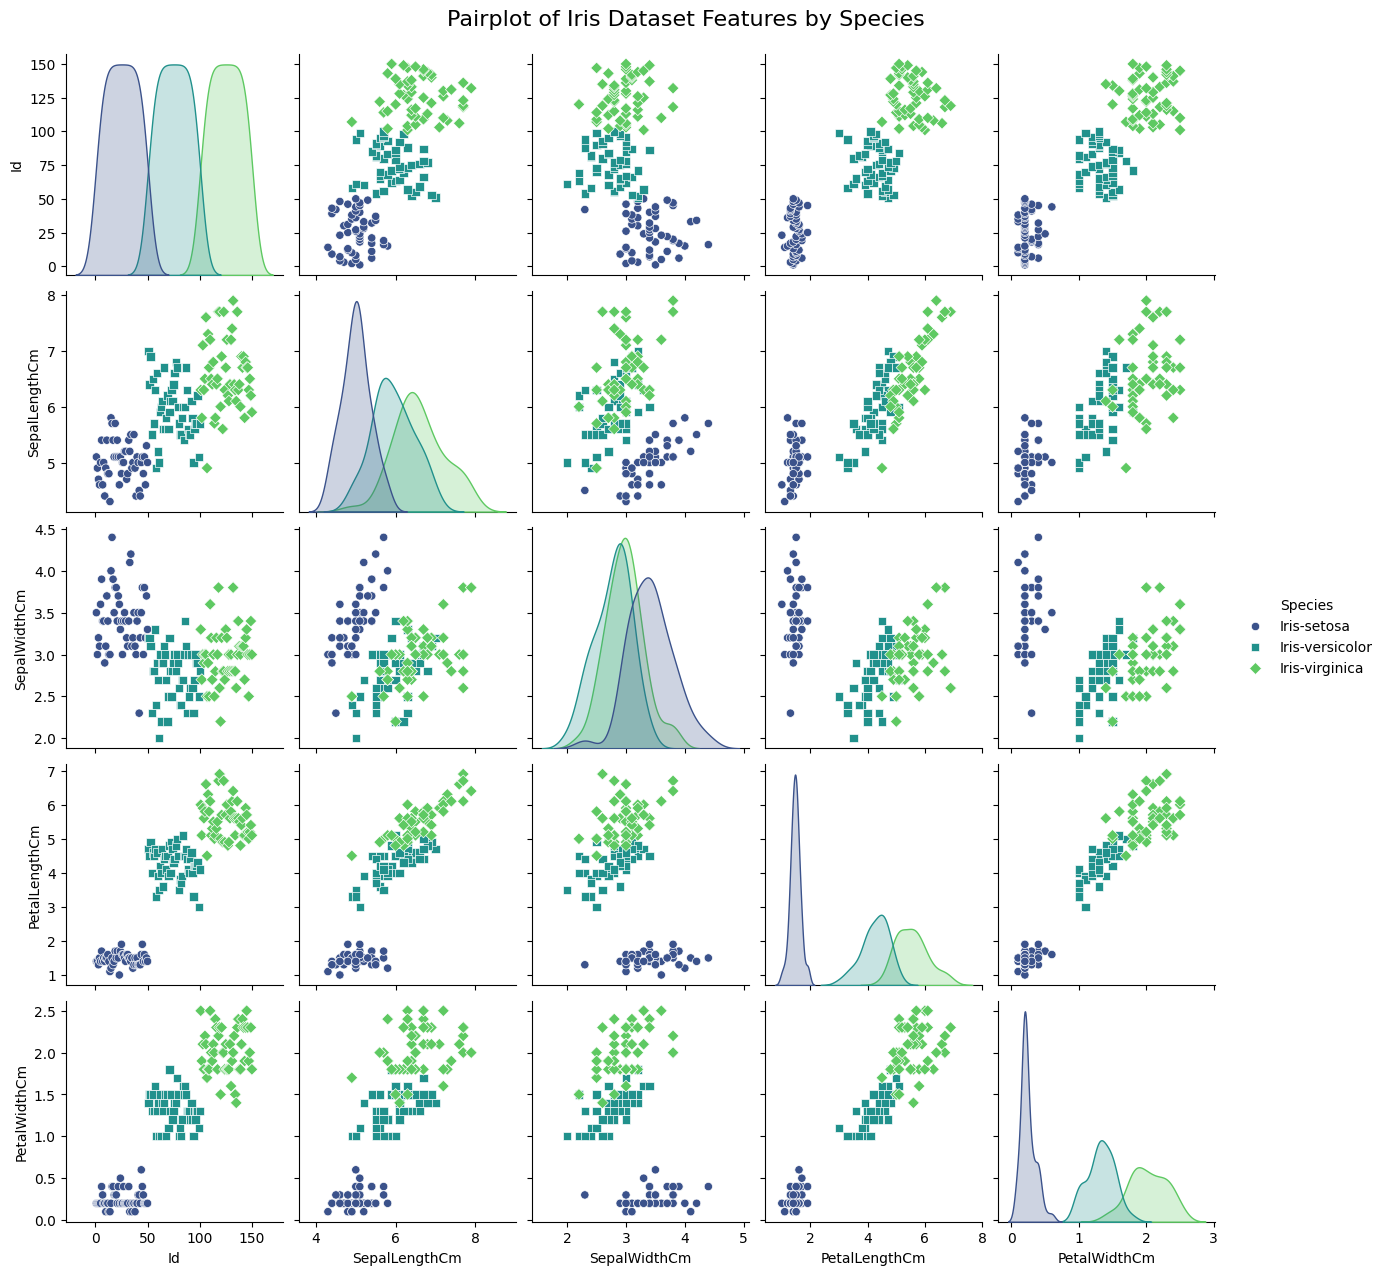

In [14]:
sns.pairplot(iris_df, hue='Species', markers=['o', 's', 'D'], palette='viridis')
plt.suptitle('Pairplot of Iris Dataset Features by Species', y=1.02, fontsize=16)
plt.show()

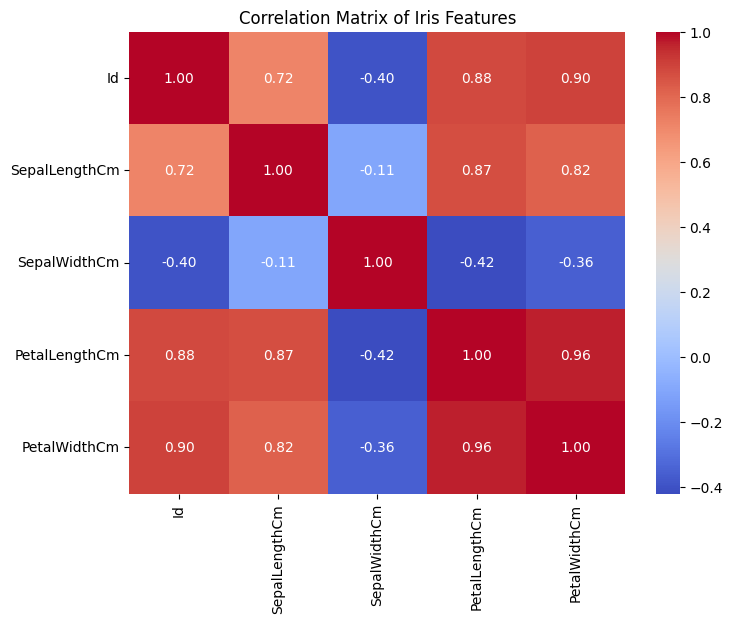

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(iris_df.drop('Species', axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Iris Features')
plt.show()

### Data Transformation: Feature Scaling

We will use `StandardScaler` to scale the numerical features (`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`) of the Iris dataset. This ensures that each feature contributes equally to the analysis and prevents features with larger values from dominating algorithms that rely on distance metrics.

In [16]:
from sklearn.preprocessing import StandardScaler

features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = iris_df[features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

iris_scaled_df = pd.DataFrame(X_scaled, columns=features)

iris_scaled_df['Species'] = iris_df['Species']

print('Scaled DataFrame head:')
display(iris_scaled_df.head())

print('\nScaled DataFrame description:')
display(iris_scaled_df.describe())

Scaled DataFrame head:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,-0.900681,1.032057,-1.341272,-1.312977,Iris-setosa
1,-1.143017,-0.124958,-1.341272,-1.312977,Iris-setosa
2,-1.385353,0.337848,-1.398138,-1.312977,Iris-setosa
3,-1.506521,0.106445,-1.284407,-1.312977,Iris-setosa
4,-1.021849,1.263460,-1.341272,-1.312977,Iris-setosa



Scaled DataFrame description:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,1.500000e+02,1.500000e+02,1.500000e+02,1.500000e+02
mean,-4.736952e-16,-6.631732e-16,3.315866e-16,-2.842171e-16
std,1.003350e+00,1.003350e+00,1.003350e+00,1.003350e+00
min,-1.870024e+00,-2.438987e+00,-1.568735e+00,-1.444450e+00
25%,-9.006812e-01,-5.877635e-01,-1.227541e+00,-1.181504e+00
50%,-5.250608e-02,-1.249576e-01,3.362659e-01,1.332259e-01
75%,6.745011e-01,5.692513e-01,7.627586e-01,7.905908e-01
max,2.492019e+00,3.114684e+00,1.786341e+00,1.710902e+00


### Outlier Detection (using Isolation Forest)

While the Iris dataset is relatively clean, we can still apply an outlier detection model like **Isolation Forest** to identify potential anomalies based on the numerical features. This algorithm works by isolating observations by randomly selecting a feature and then randomly selecting a split value between the maximum and minimum values of the selected feature.

Identified Outliers:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,outlier_score
13,14,4.3,3.0,1.1,0.1,Iris-setosa,-1
14,15,5.8,4.0,1.2,0.2,Iris-setosa,-1
15,16,5.7,4.4,1.5,0.4,Iris-setosa,-1
41,42,4.5,2.3,1.3,0.3,Iris-setosa,-1
109,110,7.2,3.6,6.1,2.5,Iris-virginica,-1
117,118,7.7,3.8,6.7,2.2,Iris-virginica,-1
118,119,7.7,2.6,6.9,2.3,Iris-virginica,-1
131,132,7.9,3.8,6.4,2.0,Iris-virginica,-1


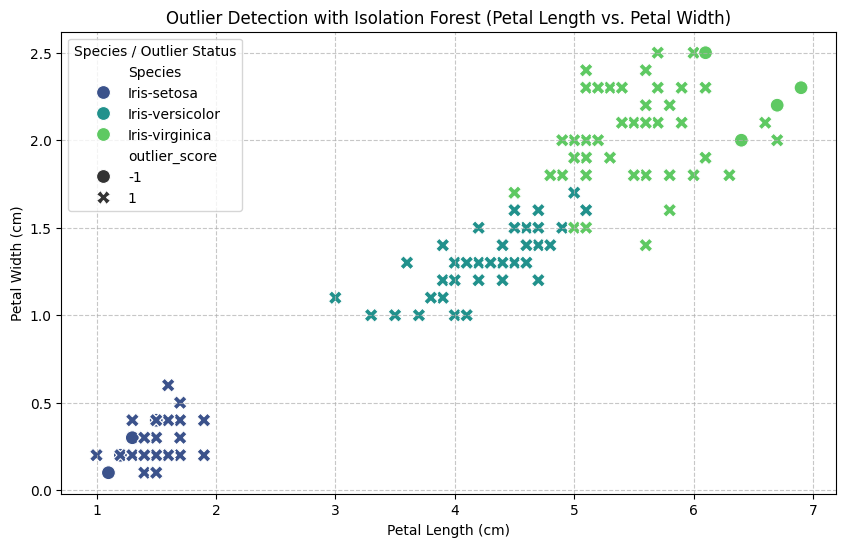

In [17]:
from sklearn.ensemble import IsolationForest

X_numerical = iris_scaled_df[features]

isolation_forest = IsolationForest(contamination=0.05, random_state=42)

iris_df['outlier_score'] = isolation_forest.fit_predict(X_numerical)

outliers = iris_df[iris_df['outlier_score'] == -1]

print('Identified Outliers:')
display(outliers)

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PetalLengthCm', y='PetalWidthCm', hue='Species', style='outlier_score', data=iris_df, palette='viridis', s=100)
plt.title('Outlier Detection with Isolation Forest (Petal Length vs. Petal Width)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Species / Outlier Status')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Dimensionality Reduction: PCA (Principal Component Analysis)

**PCA** is a technique used to reduce the dimensionality of data while retaining as much variance as possible. For the Iris dataset, we can reduce the 4 numerical features to 2 principal components to visualize the data in a 2D space, which is very useful for observing clusters.

PCA Transformed Data Head:


,Principal Component 1,Principal Component 2,Species
0,-2.264542,0.505704,Iris-setosa
1,-2.086426,-0.655405,Iris-setosa
2,-2.367950,-0.318477,Iris-setosa
3,-2.304197,-0.575368,Iris-setosa
4,-2.388777,0.674767,Iris-setosa


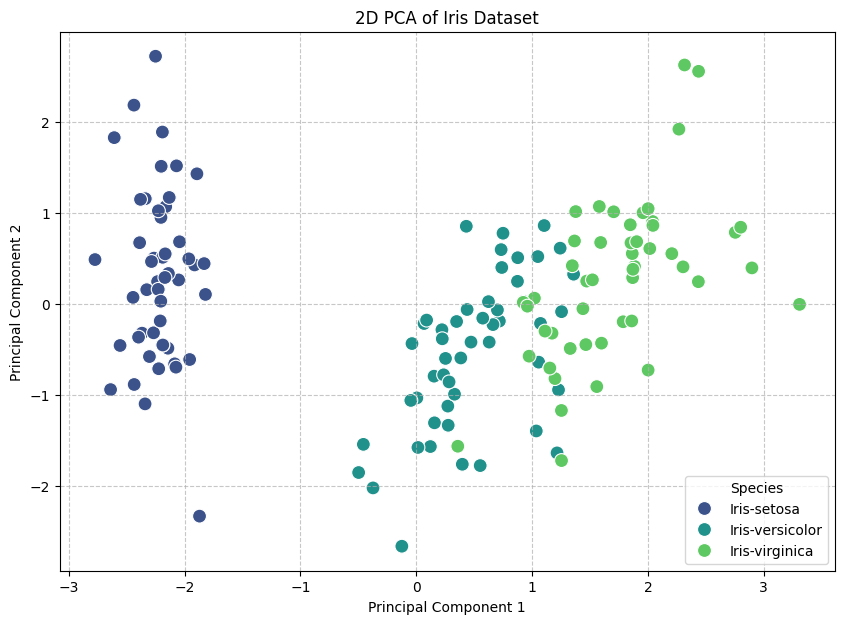

Explained variance ratio by principal components: [0.72770452 0.23030523]
Total explained variance: 0.96


In [18]:
from sklearn.decomposition import PCA

X_numerical = iris_scaled_df[features]

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_numerical)

pca_df = pd.DataFrame(data=X_pca, columns=['Principal Component 1', 'Principal Component 2'])

pca_df['Species'] = iris_df['Species']

print('PCA Transformed Data Head:')
display(pca_df.head())

plt.figure(figsize=(10, 7))
sns.scatterplot(x='Principal Component 1', y='Principal Component 2', hue='Species', data=pca_df, palette='viridis', s=100)
plt.title('2D PCA of Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print(f"Explained variance ratio by principal components: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.2f}")